In [3]:
# ============================================================
# PASO 1: IMPORTAR LIBRERÍAS
# Descripción: cargamos las herramientas necesarias para unir,
# revisar y preprocesar las bases ENDES 2021, 2022 y 2023.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [4]:
# ============================================================
# PASO 2: CARGAR BASES 2021, 2022 Y 2023
# Descripción: cargamos las tres bases previamente preparadas
# para iniciar su integración en un solo dataset.
# ============================================================

df_2021 = pd.read_excel("ENDES_PUNO_ANEMIA_2021.xlsx")
df_2022 = pd.read_excel("ENDES_PUNO_ANEMIA_2022.xlsx")
df_2023 = pd.read_excel("ENDES_PUNO_ANEMIA_2023.xlsx")

print("2021:", df_2021.shape)
print("2022:", df_2022.shape)
print("2023:", df_2023.shape)

2021: (328, 85)
2022: (318, 85)
2023: (277, 85)


In [5]:
# ============================================================
# PASO 3: VERIFICAR ESTRUCTURA DE LAS BASES
# Descripción: comprobamos cuántas variables tiene cada año
# y revisamos si las columnas son compatibles.
# ============================================================

print("Columnas 2021:", len(df_2021.columns))
print("Columnas 2022:", len(df_2022.columns))
print("Columnas 2023:", len(df_2023.columns))

print("\n¿2021 y 2022 tienen las mismas columnas?",
      set(df_2021.columns) == set(df_2022.columns))

print("¿2021 y 2023 tienen las mismas columnas?",
      set(df_2021.columns) == set(df_2023.columns))

Columnas 2021: 85
Columnas 2022: 85
Columnas 2023: 85

¿2021 y 2022 tienen las mismas columnas? False
¿2021 y 2023 tienen las mismas columnas? False


In [6]:
# ============================================================
# PASO 4: IDENTIFICAR DIFERENCIAS ENTRE AÑOS
# Descripción: mostramos las variables que aparecen en un año
# pero no en otro antes de realizar la unión.
# ============================================================

solo_2021 = set(df_2021.columns) - set(df_2022.columns)
solo_2022 = set(df_2022.columns) - set(df_2021.columns)

print("Variables solo en 2021:")
print(solo_2021)

print("\nVariables solo en 2022:")
print(solo_2022)

Variables solo en 2021:
{'latitudy', 'longitudx', 'ID1', 'ï»¿ID1'}

Variables solo en 2022:
{'LONGITUDX', 'ID1_RECH0', 'LATITUDY', 'ID1_RECH6'}


In [7]:
solo_2021_vs_2023 = set(df_2021.columns) - set(df_2023.columns)
solo_2023 = set(df_2023.columns) - set(df_2021.columns)

print("Variables solo en 2021 respecto a 2023:")
print(solo_2021_vs_2023)

print("\nVariables solo en 2023:")
print(solo_2023)

Variables solo en 2021 respecto a 2023:
{'latitudy', 'longitudx', 'ID1', 'ï»¿ID1'}

Variables solo en 2023:
{'LONGITUDX', 'ID1_nino', 'LATITUDY', 'ID1_hogar'}


In [8]:
# ============================================================
# PASO 5: ESTANDARIZAR NOMBRES DE COLUMNAS
# Descripción: unificamos los nombres que cambian entre años
# para poder integrar las tres bases sin duplicar variables.
# ============================================================

# ---- 2021 ----
df_2021 = df_2021.rename(columns={
    "ï»¿ID1": "ID1_RECH6",
    "ID1": "ID1_RECH0",
    "latitudy": "LATITUDY",
    "longitudx": "LONGITUDX"
})

# ---- 2022 ----
# Ya utiliza ID1_RECH0, ID1_RECH6, LATITUDY y LONGITUDX

# ---- 2023 ----
df_2023 = df_2023.rename(columns={
    "ID1_hogar": "ID1_RECH0",
    "ID1_nino": "ID1_RECH6"
})

print("Nombres de columnas estandarizados.")

Nombres de columnas estandarizados.


In [9]:
# ============================================================
# PASO 6: VERIFICAR COMPATIBILIDAD
# Descripción: comprobamos nuevamente si las tres bases
# contienen las mismas variables después de estandarizarlas.
# ============================================================

print("2021 vs 2022:",
      set(df_2021.columns) == set(df_2022.columns))

print("2021 vs 2023:",
      set(df_2021.columns) == set(df_2023.columns))

print("2022 vs 2023:",
      set(df_2022.columns) == set(df_2023.columns))


2021 vs 2022: True
2021 vs 2023: True
2022 vs 2023: True


In [10]:
# ============================================================
# PASO 7: CREAR VARIABLE AÑO
# Descripción: agregamos una variable que permita identificar
# de qué ENDES proviene cada registro.
# ============================================================

df_2021["anio"] = 2021
df_2022["anio"] = 2022
df_2023["anio"] = 2023

print("Variable 'anio' agregada correctamente.")

Variable 'anio' agregada correctamente.


In [11]:
# ============================================================
# PASO 8: INTEGRAR LOS TRES AÑOS
# Descripción: combinamos verticalmente las bases 2021, 2022
# y 2023 para construir un único dataset de análisis.
# ============================================================

df_endes = pd.concat(
    [df_2021, df_2022, df_2023],
    ignore_index=True
)

print("Dataset integrado:")
print(df_endes.shape)

Dataset integrado:
(923, 86)


In [12]:
# ============================================================
# PASO 9: VERIFICAR REGISTROS POR AÑO
# Descripción: comprobamos que todos los registros hayan sido
# integrados correctamente.
# ============================================================

print(df_endes["anio"].value_counts().sort_index())

anio
2021    328
2022    318
2023    277
Name: count, dtype: int64


In [13]:
# ============================================================
# PASO 10: REVISAR REGISTROS DUPLICADOS
# Descripción: verificamos si existen filas completamente
# repetidas dentro del dataset integrado.
# ============================================================

duplicados = df_endes.duplicated().sum()

print("Registros duplicados encontrados:", duplicados)

Registros duplicados encontrados: 0


In [14]:
# ============================================================
# PASO 11: REVISAR VALORES FALTANTES
# Descripción: identificamos cuántos valores vacíos existen
# en cada variable del dataset integrado.
# ============================================================

faltantes = df_endes.isnull().sum()

faltantes = faltantes[
    faltantes > 0
].sort_values(ascending=False)

print("Variables con valores faltantes:")
print(faltantes)

Variables con valores faltantes:
Series([], dtype: int64)


In [15]:
# ============================================================
# PASO 12: PORCENTAJE DE VALORES FALTANTES
# Descripción: calculamos qué porcentaje de información falta
# en cada variable para decidir posteriormente su tratamiento.
# ============================================================

porcentaje_faltantes = (
    df_endes.isnull().mean() * 100
).round(2)

tabla_faltantes = pd.DataFrame({
    "Cantidad_faltante": df_endes.isnull().sum(),
    "Porcentaje_faltante": porcentaje_faltantes
})

tabla_faltantes = tabla_faltantes[
    tabla_faltantes["Cantidad_faltante"] > 0
].sort_values(
    "Porcentaje_faltante",
    ascending=False
)

tabla_faltantes

,Cantidad_faltante,Porcentaje_faltante


In [16]:
# ============================================================
# PASO 13: VERIFICAR VARIABLE OBJETIVO
# Descripción: comprobamos la distribución total de anemia
# después de integrar los años 2021, 2022 y 2023.
# ============================================================

print("Distribución total de target_anemia:")
print(df_endes["target_anemia"].value_counts())

print("\nDistribución porcentual:")
print(
    (
        df_endes["target_anemia"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

Distribución total de target_anemia:
target_anemia
1    640
0    283
Name: count, dtype: int64

Distribución porcentual:
target_anemia
1    69.34
0    30.66
Name: proportion, dtype: float64


In [17]:
# ============================================================
# PASO 14: REVISAR VALORES FALTANTES
# Descripción: identificamos las variables que contienen
# información faltante y calculamos su porcentaje.
# ============================================================

tabla_faltantes = pd.DataFrame({
    "Faltantes": df_endes.isnull().sum(),
    "Porcentaje": (df_endes.isnull().mean() * 100).round(2)
})

tabla_faltantes = tabla_faltantes[
    tabla_faltantes["Faltantes"] > 0
].sort_values(
    "Porcentaje",
    ascending=False
)

tabla_faltantes

,Faltantes,Porcentaje


923 registros
86 variables
0 valores faltantes detectados como NaN

In [18]:
# ============================================================
# PASO 16: RESUMEN GENERAL DE FALTANTES
# Descripción: mostramos cuántas variables presentan datos
# incompletos dentro del dataset integrado.
# ============================================================

print("Total de variables:", df_endes.shape[1])
print("Variables con faltantes:", len(tabla_faltantes))
print("Variables sin faltantes:", df_endes.shape[1] - len(tabla_faltantes))

Total de variables: 86
Variables con faltantes: 0
Variables sin faltantes: 86


In [19]:
# ============================================================
# PASO 15: BUSCAR CÓDIGOS ESPECIALES
# Descripción: identificamos valores utilizados por ENDES para
# representar casos no válidos, no sabe, no aplica o no medidos.
# ============================================================

codigos_especiales = [9, 98, 99, 998, 999, 9998, 9999, 99998]

resultados = []

for columna in df_endes.select_dtypes(include=np.number).columns:
    for codigo in codigos_especiales:
        cantidad = (df_endes[columna] == codigo).sum()

        if cantidad > 0:
            resultados.append({
                "Variable": columna,
                "Codigo": codigo,
                "Cantidad": cantidad
            })

tabla_codigos = pd.DataFrame(resultados)

tabla_codigos

,Variable,Codigo,Cantidad
0,HV002,9,13
1,HV002,98,2
2,HV002,99,5
3,HV009,9,7
4,HV012,9,7
5,HV013,9,7
6,CODCCPP,9,12
7,CODCCPP,98,1
8,HC0,9,5
9,HC1,9,38


In [20]:
# ============================================================
# PASO 16: RESUMEN DE CÓDIGOS ESPECIALES
# Descripción: mostramos las variables con mayor cantidad
# de códigos especiales para decidir su tratamiento.
# ============================================================

if len(tabla_codigos) > 0:
    display(
        tabla_codigos
        .sort_values("Cantidad", ascending=False)
        .head(30)
    )
else:
    print("No se encontraron códigos especiales.")

,Variable,Codigo,Cantidad
35,HC30,9,72
9,HC1,9,38
41,HC64,99,35
39,HC56,99,30
34,HC16,9,23
38,HC56,98,23
11,HC2,99,16
0,HV002,9,13
6,CODCCPP,9,12
40,HC61,9,11


“No se identificaron valores faltantes representados como NaN en el dataset integrado. Posteriormente, se realizó una revisión de códigos especiales utilizados en los microdatos ENDES para identificar valores no válidos, no aplicables o no especificados.”

In [21]:
# ============================================================
# PASO 17: REVISAR VARIABLES DISPONIBLES
# Descripción: mostramos todas las variables del dataset para
# seleccionar posteriormente las características predictoras.
# ============================================================

for i, columna in enumerate(df_endes.columns, start=1):
    print(f"{i}. {columna}")

1. ID1_RECH0
2. HHID
3. HV000
4. HV001
5. HV002
6. HV002A
7. HV003
8. HV004
9. HV007
10. HV008
11. HV009
12. HV010
13. HV011
14. HV012
15. HV013
16. HV014
17. HV015
18. HV017
19. HV020
20. HV021
21. HV023
22. HV024
23. HV025
24. HV026
25. HV027
26. HV028
27. HV030
28. HV031
29. HV032
30. HV033
31. HV035
32. HV040
33. HV041
34. HV042
35. HV043
36. HV044
37. UBIGEO
38. HV022
39. CODCCPP
40. NOMCCPP
41. NCONGLOME
42. HV005
43. LONGITUDX
44. LATITUDY
45. ID1_RECH6
46. HC0
47. HC1
48. HC2
49. HC3
50. HC4
51. HC5
52. HC6
53. HC7
54. HC8
55. HC9
56. HC10
57. HC11
58. HC12
59. HC13
60. HC15
61. HC16
62. HC19
63. HC27
64. HC30
65. HC31
66. HC32
67. HC33
68. HC51
69. HC52
70. HC53
71. HC55
72. HC56
73. HC57
74. HC58
75. HC60
76. HC61
77. HC62
78. HC63
79. HC64
80. HC68
81. HC70
82. HC71
83. HC72
84. HC73
85. target_anemia
86. anio


In [22]:
# ============================================================
# PASO 18: SELECCIONAR VARIABLES PARA EL MODELO
# Descripción: conservamos variables relacionadas con el niño,
# madre y hogar, excluyendo identificadores y variables que
# revelan directamente el diagnóstico de anemia.
# ============================================================

variables_modelo = [
    "HC1",             # Edad del niño en meses
    "HC61",            # Sexo del niño
    "HC2",             # Peso
    "HC3",             # Talla
    "HC52",            # Nivel educativo de la madre
    "HV009",           # Total de personas en el hogar
    "HV012",           # Residentes habituales
    "HV014",           # Niños menores de 5 años en el hogar
    "HV025",           # Área de residencia
    "HV023",           # Dominio geográfico
    "HV022",           # Estrato
    "anio",            # Año de la ENDES
    "target_anemia"    # Variable objetivo
]

df_modelo = df_endes[variables_modelo].copy()

print("Dataset para modelado:")
print(df_modelo.shape)

df_modelo.head()

Dataset para modelado:
(923, 13)


,HC1,HC61,HC2,HC3,HC52,HV009,HV012,HV014,HV025,HV023,HV022,anio,target_anemia
0,8,3,111,740,1,4,4,1,1,21,201,2021,1
1,30,3,130,919,1,3,3,1,1,21,201,2021,0
2,23,2,109,866,1,4,4,1,1,21,201,2021,1
3,27,9,147,934,1,2,2,1,1,21,202,2021,1
4,34,3,151,948,1,4,4,1,1,21,202,2021,0


In [23]:
# ============================================================
# PASO 19: REVISAR FALTANTES EN VARIABLES SELECCIONADAS
# Descripción: comprobamos si las variables elegidas presentan
# valores vacíos antes de realizar su transformación.
# ============================================================

faltantes_modelo = pd.DataFrame({
    "Faltantes": df_modelo.isnull().sum(),
    "Porcentaje": (
        df_modelo.isnull().mean() * 100
    ).round(2)
})

faltantes_modelo

,Faltantes,Porcentaje
HC1,0,0.0
HC61,0,0.0
HC2,0,0.0
HC3,0,0.0
HC52,0,0.0
HV009,0,0.0
HV012,0,0.0
HV014,0,0.0
HV025,0,0.0
HV023,0,0.0


In [24]:
# ============================================================
# PASO 20: REVISAR VALORES DE LAS VARIABLES
# Descripción: mostramos los valores presentes en cada variable
# seleccionada para detectar códigos especiales o inconsistentes.
# ============================================================

for columna in df_modelo.columns:

    print("\n" + "=" * 50)
    print("VARIABLE:", columna)

    print(
        df_modelo[columna]
        .value_counts(dropna=False)
        .sort_index()
        .head(30)
    )


VARIABLE: HC1
HC1
6     36
7     29
8     32
9     38
10    32
11    27
12    37
13    21
14    30
15    22
16    39
17    32
18    37
19    26
20    33
21    42
22    21
23    19
24    28
25    25
26    25
27    31
28    39
29    30
30    32
31    35
32    32
33    32
34    23
35    38
Name: count, dtype: int64

VARIABLE: HC61
HC61
0      3
1    134
2    647
3    128
9     11
Name: count, dtype: int64

VARIABLE: HC2
HC2
52     1
57     1
60     2
61     1
62     1
64     1
66     1
67     1
68     1
70     2
71     6
72     7
73     3
74     3
75     5
76     4
77     5
78     8
79     6
80     9
81     8
82     9
83    19
84     8
85    10
86    19
87    10
88    14
89    10
90    14
Name: count, dtype: int64

VARIABLE: HC3
HC3
598    1
603    1
610    1
617    1
623    1
626    1
627    1
632    2
633    1
638    1
639    1
640    1
641    2
642    1
644    1
645    2
646    2
647    1
649    3
651    2
654    2
655    3
657    1
659    1
662    1
663    1
664    5
665    3
666    

In [25]:
# ============================================================
# PASO 21: REVISAR VARIABLES CLAVE
# Descripción: verificamos sexo, educación materna y otras
# variables antes de construir el dataset definitivo.
# ============================================================

variables_revisar = [
    "HC27",   # Sexo del niño
    "HC61",   # Nivel educativo de la madre
    "HC68",   # Nivel educativo final de la madre
    "HV025",  # Área de residencia
    "HV022"   # Estrato
]

for variable in variables_revisar:
    print("\n" + "=" * 45)
    print("VARIABLE:", variable)
    print(df_endes[variable].value_counts(dropna=False).sort_index())


VARIABLE: HC27
HC27
1    486
2    437
Name: count, dtype: int64

VARIABLE: HC61
HC61
0      3
1    134
2    647
3    128
9     11
Name: count, dtype: int64

VARIABLE: HC68
HC68
      11
0      3
1    134
2    647
3    128
Name: count, dtype: int64

VARIABLE: HV025
HV025
1    449
2    474
Name: count, dtype: int64

VARIABLE: HV022
HV022
201     17
202     30
203     29
204     18
206     13
207     36
208     72
209    154
210     80
211    474
Name: count, dtype: int64


In [26]:
# ============================================================
# PASO 22: CREAR DATASET DE PREDICTORES
# Descripción: seleccionamos variables útiles del niño,
# madre y hogar, evitando identificadores y fuga de información.
# ============================================================

variables_modelo = [
    # Características del niño
    "HC1",       # Edad en meses
    "HC27",      # Sexo
    "HC2",       # Peso
    "HC3",       # Talla

    # Características maternas
    "HC68",      # Nivel educativo de la madre

    # Características del hogar
    "HV009",     # Total de personas en el hogar
    "HV012",     # Residentes habituales
    "HV014",     # Niños menores de 5 años
    "HV025",     # Área urbana/rural
    "HV022",     # Estrato

    # Contexto temporal
    "anio",

    # Variable objetivo
    "target_anemia"
]

df_modelo = df_endes[variables_modelo].copy()

print("Dimensión del dataset seleccionado:")
print(df_modelo.shape)

df_modelo.head()

Dimensión del dataset seleccionado:
(923, 12)


,HC1,HC27,HC2,HC3,HC68,HV009,HV012,HV014,HV025,HV022,anio,target_anemia
0,8,1,111,740,3,4,4,1,1,201,2021,1
1,30,1,130,919,3,3,3,1,1,201,2021,0
2,23,2,109,866,2,4,4,1,1,201,2021,1
3,27,1,147,934,,2,2,1,1,202,2021,1
4,34,1,151,948,3,4,4,1,1,202,2021,0


In [27]:
# ============================================================
# PASO 23: CONTROL FINAL DE VARIABLES
# Descripción: verificamos tipos de datos, faltantes y valores
# únicos antes de realizar la codificación.
# ============================================================

resumen_variables = pd.DataFrame({
    "Tipo": df_modelo.dtypes,
    "Valores_unicos": df_modelo.nunique(),
    "Faltantes": df_modelo.isnull().sum()
})

resumen_variables

,Tipo,Valores_unicos,Faltantes
HC1,int64,30,0
HC27,int64,2,0
HC2,int64,106,0
HC3,int64,303,0
HC68,object,5,0
HV009,int64,11,0
HV012,int64,11,0
HV014,int64,3,0
HV025,int64,2,0
HV022,int64,10,0


In [28]:
# ============================================================
# PASO 24: REVISAR EDUCACIÓN MATERNA
# Descripción: verificamos los valores reales de HC68 antes
# de transformarla a una variable numérica/categórica.
# ============================================================

print("Valores encontrados en HC68:")
print(
    df_modelo["HC68"]
    .value_counts(dropna=False)
    .sort_index()
)

Valores encontrados en HC68:
HC68
      11
0      3
1    134
2    647
3    128
Name: count, dtype: int64


In [29]:
# ============================================================
# PASO 25: REVISAR VARIABLES CATEGÓRICAS
# Descripción: comprobamos los códigos presentes en sexo,
# área de residencia, estrato y año antes de codificarlos.
# ============================================================

for variable in ["HC27", "HC68", "HV025", "HV022", "anio"]:
    print("\n" + "=" * 40)
    print(variable)
    print(df_modelo[variable].value_counts(dropna=False).sort_index())


HC27
HC27
1    486
2    437
Name: count, dtype: int64

HC68
HC68
      11
0      3
1    134
2    647
3    128
Name: count, dtype: int64

HV025
HV025
1    449
2    474
Name: count, dtype: int64

HV022
HV022
201     17
202     30
203     29
204     18
206     13
207     36
208     72
209    154
210     80
211    474
Name: count, dtype: int64

anio
anio
2021    328
2022    318
2023    277
Name: count, dtype: int64


In [30]:
# ============================================================
# PASO 26: AJUSTAR PESO Y TALLA
# Descripción: convertimos las variables almacenadas con
# un decimal implícito a kilogramos y centímetros reales.
# ============================================================

df_modelo["peso_kg"] = df_modelo["HC2"] / 10
df_modelo["talla_cm"] = df_modelo["HC3"] / 10

# Eliminamos las versiones originales para evitar duplicarlas
df_modelo = df_modelo.drop(columns=["HC2", "HC3"])

print(df_modelo[["peso_kg", "talla_cm"]].describe())

          peso_kg    talla_cm
count  923.000000  923.000000
mean    10.991874   80.262622
std      2.128907    8.274184
min      5.200000   59.800000
25%      9.300000   73.450000
50%     10.900000   80.700000
75%     12.500000   86.850000
max     20.000000   99.100000


In [31]:
# ============================================================
# PASO 27: VERIFICAR RANGOS
# Descripción: revisamos mínimos y máximos para detectar
# posibles valores fuera de los rangos esperados.
# ============================================================

variables_numericas = [
    "HC1",
    "peso_kg",
    "talla_cm",
    "HV009",
    "HV012",
    "HV014"
]

for variable in variables_numericas:
    print(
        variable,
        "-> mínimo:", df_modelo[variable].min(),
        "| máximo:", df_modelo[variable].max()
    )

HC1 -> mínimo: 6 | máximo: 35
peso_kg -> mínimo: 5.2 | máximo: 20.0
talla_cm -> mínimo: 59.8 | máximo: 99.1
HV009 -> mínimo: 2 | máximo: 12
HV012 -> mínimo: 2 | máximo: 12
HV014 -> mínimo: 1 | máximo: 3


In [32]:
# ============================================================
# PASO 28: LIMPIAR EDUCACIÓN MATERNA
# Descripción: reemplazamos valores vacíos de HC68 por
# "No informado" para evitar perder registros.
# ============================================================

df_modelo["HC68"] = (
    df_modelo["HC68"]
    .astype(str)
    .str.strip()
)

df_modelo["HC68"] = df_modelo["HC68"].replace(
    ["", "nan", "None"],
    "No informado"
)

print(df_modelo["HC68"].value_counts(dropna=False))

HC68
2               647
1               134
3               128
No informado     11
0                 3
Name: count, dtype: int64


In [33]:
# ============================================================
# PASO 29: ETIQUETAR VARIABLES CATEGÓRICAS
# Descripción: convertimos códigos ENDES en categorías
# comprensibles antes de realizar la codificación.
# ============================================================

# Sexo del niño
df_modelo["sexo"] = df_modelo["HC27"].map({
    1: "Hombre",
    2: "Mujer"
})

# Área de residencia
df_modelo["area_residencia"] = df_modelo["HV025"].map({
    1: "Urbana",
    2: "Rural"
})

# Educación materna
mapa_educacion = {
    "0": "Sin educación",
    "1": "Primaria",
    "2": "Secundaria",
    "3": "Superior",
    "8": "No sabe",
    "No informado": "No informado"
}

df_modelo["educacion_madre"] = df_modelo["HC68"].map(mapa_educacion)

# Estrato como categoría
df_modelo["estrato"] = df_modelo["HV022"].astype(str)

# Año como categoría
df_modelo["anio_cat"] = df_modelo["anio"].astype(str)

print("Variables categóricas creadas correctamente.")

Variables categóricas creadas correctamente.


In [34]:
# ============================================================
# PASO 30: ELIMINAR VARIABLES ORIGINALES CODIFICADAS
# Descripción: retiramos los códigos numéricos originales para
# evitar duplicar la misma información.
# ============================================================

df_modelo = df_modelo.drop(
    columns=[
        "HC27",
        "HC68",
        "HV025",
        "HV022",
        "anio"
    ]
)

print("Dimensión actual:", df_modelo.shape)
print(df_modelo.columns.tolist())

Dimensión actual: (923, 12)
['HC1', 'HV009', 'HV012', 'HV014', 'target_anemia', 'peso_kg', 'talla_cm', 'sexo', 'area_residencia', 'educacion_madre', 'estrato', 'anio_cat']


In [35]:
# ============================================================
# PASO 31: CONTROL DE CALIDAD
# Descripción: comprobamos que no existan valores vacíos
# después de las transformaciones realizadas.
# ============================================================

print("Valores faltantes por variable:")
print(df_modelo.isnull().sum())

print("\nDimensión:")
print(df_modelo.shape)

print("\nTipos de datos:")
print(df_modelo.dtypes)

Valores faltantes por variable:
HC1                0
HV009              0
HV012              0
HV014              0
target_anemia      0
peso_kg            0
talla_cm           0
sexo               0
area_residencia    0
educacion_madre    0
estrato            0
anio_cat           0
dtype: int64

Dimensión:
(923, 12)

Tipos de datos:
HC1                  int64
HV009                int64
HV012                int64
HV014                int64
target_anemia        int64
peso_kg            float64
talla_cm           float64
sexo                object
area_residencia     object
educacion_madre     object
estrato             object
anio_cat            object
dtype: object


In [36]:
# ============================================================
# PASO 32: CODIFICAR VARIABLES CATEGÓRICAS
# Descripción: aplicamos One-Hot Encoding para transformar las
# variables categóricas en formato compatible con el modelo.
# ============================================================

variables_categoricas = [
    "sexo",
    "area_residencia",
    "educacion_madre",
    "estrato",
    "anio_cat"
]

df_procesado = pd.get_dummies(
    df_modelo,
    columns=variables_categoricas,
    drop_first=False,
    dtype=int
)

print("Dataset codificado:")
print(df_procesado.shape)

df_procesado.head()

Dataset codificado:
(923, 29)


,HC1,HV009,HV012,HV014,target_anemia,peso_kg,talla_cm,sexo_Hombre,sexo_Mujer,area_residencia_Rural,...,estrato_204,estrato_206,estrato_207,estrato_208,estrato_209,estrato_210,estrato_211,anio_cat_2021,anio_cat_2022,anio_cat_2023
0,8,4,4,1,1,11.1,74.0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,30,3,3,1,0,13.0,91.9,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,23,4,4,1,1,10.9,86.6,0,1,0,...,0,0,0,0,0,0,0,1,0,0
3,27,2,2,1,1,14.7,93.4,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,34,4,4,1,0,15.1,94.8,1,0,0,...,0,0,0,0,0,0,0,1,0,0


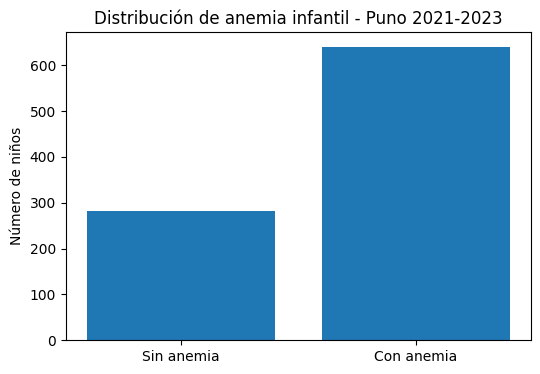

In [37]:
# ============================================================
# PASO 33: GRÁFICO DE DISTRIBUCIÓN DE ANEMIA
# Descripción: mostramos la proporción de niños con anemia
# y sin anemia en el dataset integrado 2021-2023.
# ============================================================

conteo_anemia = df_endes["target_anemia"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Sin anemia", "Con anemia"],
    [conteo_anemia[0], conteo_anemia[1]]
)

plt.title("Distribución de anemia infantil - Puno 2021-2023")
plt.ylabel("Número de niños")

plt.show()

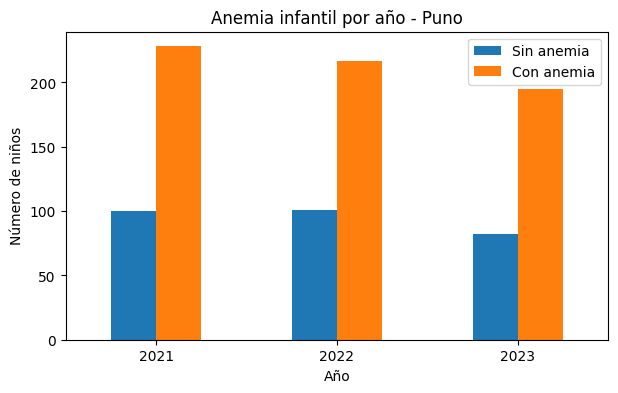

In [38]:
# ============================================================
# PASO 34: ANEMIA POR AÑO
# Descripción: comparamos la cantidad de casos con y sin
# anemia en los años 2021, 2022 y 2023.
# ============================================================

tabla_anio = pd.crosstab(
    df_endes["anio"],
    df_endes["target_anemia"]
)

tabla_anio.columns = ["Sin anemia", "Con anemia"]

tabla_anio.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Anemia infantil por año - Puno")
plt.xlabel("Año")
plt.ylabel("Número de niños")
plt.xticks(rotation=0)

plt.show()

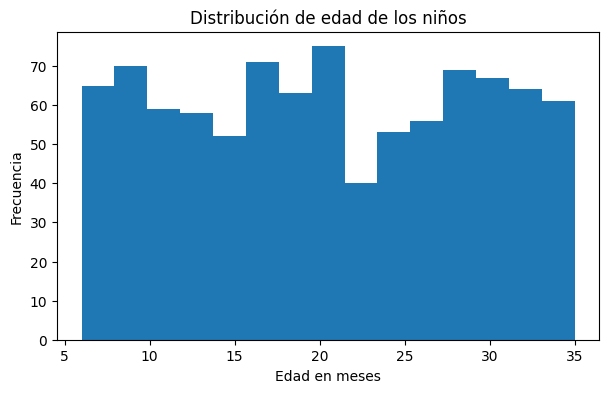

In [39]:
# ============================================================
# PASO 35: DISTRIBUCIÓN DE EDAD
# Descripción: observamos la distribución de edades de los
# niños incluidos en el estudio.
# ============================================================

plt.figure(figsize=(7, 4))

plt.hist(
    df_endes["HC1"],
    bins=15
)

plt.title("Distribución de edad de los niños")
plt.xlabel("Edad en meses")
plt.ylabel("Frecuencia")

plt.show()

In [40]:
# ============================================================
# PASO 36: RESUMEN FINAL DEL PREPROCESAMIENTO
# Descripción: mostramos las dimensiones y distribución de
# la variable objetivo antes de exportar el dataset.
# ============================================================

print("RESUMEN FINAL DEL DATASET PROCESADO")
print("-" * 45)

print("Registros:", df_procesado.shape[0])
print("Variables:", df_procesado.shape[1])

print("\nDistribución de anemia:")
print(df_procesado["target_anemia"].value_counts())

print("\nPorcentaje:")
print(
    (
        df_procesado["target_anemia"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

RESUMEN FINAL DEL DATASET PROCESADO
---------------------------------------------
Registros: 923
Variables: 29

Distribución de anemia:
target_anemia
1    640
0    283
Name: count, dtype: int64

Porcentaje:
target_anemia
1    69.34
0    30.66
Name: proportion, dtype: float64


In [41]:
# ============================================================
# PASO 37: EXPORTAR DATASET PROCESADO
# Descripción: guardamos el dataset final preparado para
# utilizarlo posteriormente en el modelo Deep Learning.
# ============================================================

nombre_archivo = "ENDES_PUNO_2021_2023_PROCESADO.xlsx"

df_procesado.to_excel(
    nombre_archivo,
    index=False
)

print("Archivo generado correctamente:")
print(nombre_archivo)

Archivo generado correctamente:
ENDES_PUNO_2021_2023_PROCESADO.xlsx


**FASE 6**

In [42]:
# ============================================================
# PASO 38: SEPARAR VARIABLES PREDICTORAS Y VARIABLE OBJETIVO
# Descripción: separamos las características de entrada (X)
# de la variable objetivo target_anemia (y).
# ============================================================

X = df_procesado.drop(columns=["target_anemia"]).copy()
y = df_procesado["target_anemia"].copy()

print("SEPARACIÓN DE VARIABLES COMPLETADA")
print("-" * 45)

print("Registros:", X.shape[0])
print("Variables predictoras:", X.shape[1])
print("Variable objetivo:", y.name)

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

print("\nPorcentaje:")
print((y.value_counts(normalize=True) * 100).round(2))

SEPARACIÓN DE VARIABLES COMPLETADA
---------------------------------------------
Registros: 923
Variables predictoras: 28
Variable objetivo: target_anemia

Distribución de la variable objetivo:
target_anemia
1    640
0    283
Name: count, dtype: int64

Porcentaje:
target_anemia
1    69.34
0    30.66
Name: proportion, dtype: float64


Como tu dataset tiene 29 columnas y una es target_anemia, deberíamos obtener aproximadamente:
SEPARACIÓN DE VARIABLES COMPLETADA
---------------------------------------------
Registros: 923
Variables predictoras: 28
Variable objetivo: target_anemia

Distribución de la variable objetivo:
1    640
0    283

Esto significa:
X → 923 niños × 28 características
y → 923 respuestas de anemia/no anemia

In [43]:
# ============================================================
# PASO 39: DIVISIÓN TRAIN / VALIDATION / TEST
# Descripción: dividimos los datos en entrenamiento (70%),
# validación (15%) y prueba (15%), manteniendo la proporción
# de niños con y sin anemia.
# ============================================================

from sklearn.model_selection import train_test_split

# Primera división:
# 70% entrenamiento y 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Segunda división:
# el 30% temporal se divide en 15% validación y 15% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("DIVISIÓN COMPLETADA")
print("-" * 45)

print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidación:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

DIVISIÓN COMPLETADA
---------------------------------------------
Entrenamiento:
X_train: (646, 28)
y_train: (646,)

Validación:
X_val: (138, 28)
y_val: (138,)

Prueba:
X_test: (139, 28)
y_test: (139,)


In [44]:
# ============================================================
# PASO 40: VERIFICAR DISTRIBUCIÓN DE CLASES
# Descripción: comprobamos que la proporción de anemia se
# mantenga similar en train, validation y test.
# ============================================================

def mostrar_distribucion(nombre, datos):
    conteo = datos.value_counts().sort_index()
    porcentaje = (
        datos.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )

    print(f"\n{nombre}")
    print("-" * 30)
    print("Conteo:")
    print(conteo)

    print("\nPorcentaje:")
    print(porcentaje)


mostrar_distribucion("ENTRENAMIENTO", y_train)
mostrar_distribucion("VALIDACIÓN", y_val)
mostrar_distribucion("PRUEBA", y_test)


ENTRENAMIENTO
------------------------------
Conteo:
target_anemia
0    198
1    448
Name: count, dtype: int64

Porcentaje:
target_anemia
0    30.65
1    69.35
Name: proportion, dtype: float64

VALIDACIÓN
------------------------------
Conteo:
target_anemia
0    42
1    96
Name: count, dtype: int64

Porcentaje:
target_anemia
0    30.43
1    69.57
Name: proportion, dtype: float64

PRUEBA
------------------------------
Conteo:
target_anemia
0    43
1    96
Name: count, dtype: int64

Porcentaje:
target_anemia
0    30.94
1    69.06
Name: proportion, dtype: float64


In [45]:
# ============================================================
# PASO 41: NORMALIZACIÓN DE VARIABLES NUMÉRICAS
# Descripción: estandarizamos únicamente variables numéricas
# continuas. El scaler aprende SOLO del conjunto train.
# ============================================================

from sklearn.preprocessing import StandardScaler

variables_numericas = [
    "HC1",
    "HV009",
    "HV012",
    "HV014",
    "peso_kg",
    "talla_cm"
]

# Copias para conservar los datos originales
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Crear escalador
scaler = StandardScaler()

# Aprender parámetros solamente desde entrenamiento
X_train_scaled[variables_numericas] = scaler.fit_transform(
    X_train[variables_numericas]
)

# Aplicar exactamente la misma transformación
X_val_scaled[variables_numericas] = scaler.transform(
    X_val[variables_numericas]
)

X_test_scaled[variables_numericas] = scaler.transform(
    X_test[variables_numericas]
)

print("NORMALIZACIÓN COMPLETADA")
print("-" * 45)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nEjemplo de variables normalizadas:")
print(
    X_train_scaled[variables_numericas]
    .head()
    .round(3)
)

NORMALIZACIÓN COMPLETADA
---------------------------------------------
Train: (646, 28)
Validation: (138, 28)
Test: (139, 28)

Ejemplo de variables normalizadas:
       HC1  HV009  HV012  HV014  peso_kg  talla_cm
81  -1.396  0.676  0.705 -0.588   -1.059    -1.635
877  1.074  2.137  2.185  1.391    0.127     1.192
759 -0.498  0.676  0.705 -0.588   -0.537    -0.313
843  1.524  1.407  1.445 -0.588    0.506     0.791
798  0.401 -0.785 -0.776 -0.588   -0.016     0.573


In [47]:
# ============================================================
# PASO 42: DEFINIR ARQUITECTURA DEL MODELO DEEP LEARNING
# Descripción: construimos una red neuronal multicapa para
# clasificación binaria del riesgo de anemia infantil.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Semilla para reproducibilidad
tf.random.set_seed(42)

modelo = Sequential([

    # Capa de entrada: 28 variables predictoras
    Input(shape=(X_train_scaled.shape[1],)),

    # Primera capa oculta
    Dense(64, activation="relu"),
    Dropout(0.30),

    # Segunda capa oculta
    Dense(32, activation="relu"),
    Dropout(0.20),

    # Tercera capa oculta
    Dense(16, activation="relu"),

    # Salida binaria
    Dense(1, activation="sigmoid")
])

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
# ============================================================
# PASO 43: COMPILACIÓN DEL MODELO
# Descripción: definimos el optimizador, función de pérdida
# y métricas que utilizará la red durante el entrenamiento.
# ============================================================

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Modelo compilado correctamente.")

Modelo compilado correctamente.


In [49]:
# ============================================================
# PASO 44: RESUMEN DE LA ARQUITECTURA
# ============================================================

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

- Entrada: 28 variables
- Capas ocultas:
  - Dense 64
  - Dropout 0.30
  - Dense 32
  - Dropout 0.20
  - Dense 16
- Salida: 1 neurona sigmoid
- Parámetros entrenables: 4,481
- Optimizador: Adam
- Learning rate: 0.001
- Pérdida: binary_crossentropy
- Métricas: Accuracy, Precision, Recall y AUC
Con eso podemos decir que la Fase 6 está prácticamente terminada.

**Fase 7: Entrenamiento y validación del modelo.**

In [50]:
# ============================================================
# PASO 45: CONFIGURAR EARLY STOPPING
# Descripción: detenemos el entrenamiento cuando la pérdida
# de validación deja de mejorar, evitando sobreajuste.
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("EarlyStopping configurado correctamente.")

EarlyStopping configurado correctamente.


In [51]:
# ============================================================
# PASO 46: ENTRENAMIENTO DEL MODELO
# Descripción: entrenamos el modelo con los datos de train
# y utilizamos validation para controlar su generalización.
# ============================================================

historial = modelo.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=150,
    batch_size=32,

    callbacks=[
        early_stopping
    ],

    verbose=1
)

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.3375 - auc: 0.5086 - loss: 0.7997 - precision: 0.7941 - recall: 0.0603 - val_accuracy: 0.4710 - val_auc: 0.4165 - val_loss: 0.7007 - val_precision: 0.6620 - val_recall: 0.4896
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5480 - auc: 0.5161 - loss: 0.6928 - precision: 0.7086 - recall: 0.5915 - val_accuracy: 0.6812 - val_auc: 0.5061 - val_loss: 0.6699 - val_precision: 0.6912 - val_recall: 0.9792
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6734 - auc: 0.5248 - loss: 0.6614 - precision: 0.7012 - recall: 0.9219 - val_accuracy: 0.6957 - val_auc: 0.5506 - val_loss: 0.6431 - val_precision: 0.6957 - val_recall: 1.0000
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6997 - auc: 0.5378 - loss: 0.6328 - precision: 0.6978 - recall: 1.0000 - val_accuracy: 0.6957 - val_auc: 0.5728 - val_loss: 0.6187 - val_precision: 0.6957 - val_recall: 1.0000
Epoch 5/150
21/21 ━━━━━━━━━━━━━━

In [52]:
# ============================================================
# PASO 47: ÉPOCAS REALMENTE ENTRENADAS
# ============================================================

epocas_entrenadas = len(historial.history["loss"])

print(
    "Número de épocas ejecutadas:",
    epocas_entrenadas
)

Número de épocas ejecutadas: 22


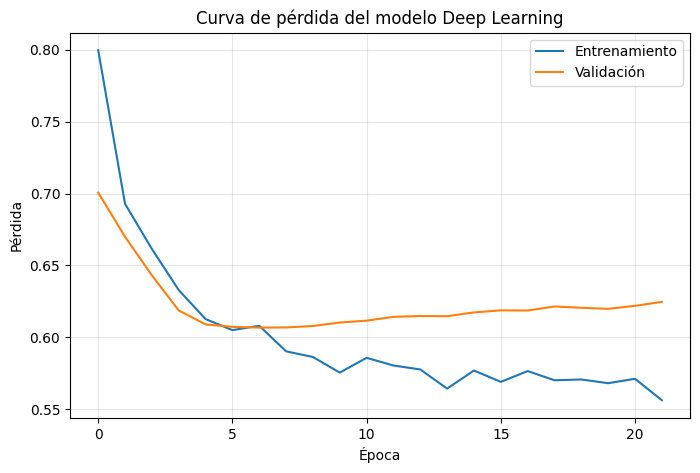

In [53]:
# ============================================================
# PASO 48: CURVA DE PÉRDIDA
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(
    historial.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial.history["val_loss"],
    label="Validación"
)

plt.xlabel("Época")
plt.ylabel("Pérdida")

plt.title(
    "Curva de pérdida del modelo Deep Learning"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

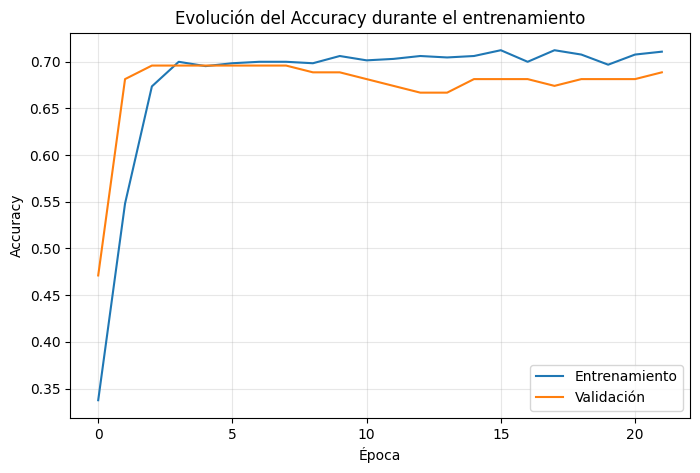

In [54]:
# ============================================================
# PASO 49: CURVA DE ACCURACY
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(
    historial.history["accuracy"],
    label="Entrenamiento"
)

plt.plot(
    historial.history["val_accuracy"],
    label="Validación"
)

plt.xlabel("Época")
plt.ylabel("Accuracy")

plt.title(
    "Evolución del Accuracy durante el entrenamiento"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [55]:
# ============================================================
# PASO 50: EVALUACIÓN FINAL SOBRE EL CONJUNTO DE PRUEBA
# Descripción: evaluamos el modelo con datos que nunca fueron
# utilizados durante el entrenamiento ni la validación.
# ============================================================

resultados_test = modelo.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("RESULTADOS DEL CONJUNTO DE PRUEBA")
print("-" * 45)

for nombre, valor in zip(modelo.metrics_names, resultados_test):
    print(f"{nombre}: {valor:.4f}")

RESULTADOS DEL CONJUNTO DE PRUEBA
---------------------------------------------
loss: 0.5983
compile_metrics: 0.6906


In [56]:
# ============================================================
# PASO 51: GENERAR PREDICCIONES
# Descripción: obtenemos la probabilidad estimada de anemia
# y la convertimos en una clasificación usando umbral 0.50.
# ============================================================

probabilidades = modelo.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_pred = (probabilidades >= 0.50).astype(int)

print("Primeras probabilidades:")
print(probabilidades[:10])

print("\nPrimeras predicciones:")
print(y_pred[:10])

Primeras probabilidades:
[0.596708   0.7546612  0.6988743  0.61804163 0.62599945 0.6595553
 0.59040946 0.62565166 0.5517216  0.62251663]

Primeras predicciones:
[1 1 1 1 1 1 1 1 1 1]


In [57]:
# ============================================================
# PASO 52: MÉTRICAS DE CLASIFICACIÓN
# Descripción: calculamos las principales métricas utilizadas
# para evaluar el desempeño predictivo del modelo.
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, probabilidades)
pr_auc = average_precision_score(y_test, probabilidades)

print("MÉTRICAS FINALES DEL MODELO")
print("-" * 45)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

MÉTRICAS FINALES DEL MODELO
---------------------------------------------
Accuracy  : 0.6906
Precision : 0.6906
Recall    : 1.0000
F1-score  : 0.8170
ROC-AUC   : 0.6417
PR-AUC    : 0.7792


Matriz de confusión:
[[ 0 43]
 [ 0 96]]


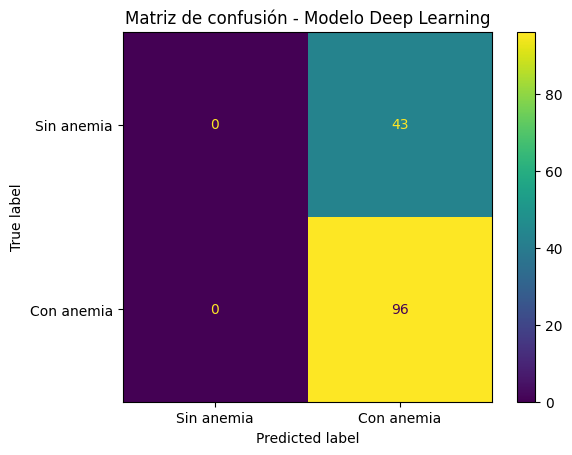

In [58]:
# ============================================================
# PASO 53: MATRIZ DE CONFUSIÓN
# Descripción: analizamos verdaderos positivos, verdaderos
# negativos, falsos positivos y falsos negativos.
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Matriz de confusión:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sin anemia", "Con anemia"]
)

disp.plot()

plt.title(
    "Matriz de confusión - Modelo Deep Learning"
)

plt.show()

In [59]:
# ============================================================
# PASO 54: REPORTE DE CLASIFICACIÓN
# ============================================================

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Sin anemia",
            "Con anemia"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Sin anemia     0.0000    0.0000    0.0000        43
  Con anemia     0.6906    1.0000    0.8170        96

    accuracy                         0.6906       139
   macro avg     0.3453    0.5000    0.4085       139
weighted avg     0.4770    0.6906    0.5643       139



In [60]:
# ============================================================
# PASO 55: CALCULAR PESOS DE CLASE
# Descripción: compensamos el desbalance entre niños con
# anemia y sin anemia asignando mayor peso a la clase minoritaria.
# ============================================================

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

clases = np.unique(y_train)

pesos = compute_class_weight(
    class_weight="balanced",
    classes=clases,
    y=y_train
)

class_weight = {
    int(clase): peso
    for clase, peso in zip(clases, pesos)
}

print("PESOS DE CLASE")
print("-" * 40)

for clase, peso in class_weight.items():
    nombre = "Sin anemia" if clase == 0 else "Con anemia"
    print(f"{clase} ({nombre}): {peso:.4f}")

PESOS DE CLASE
----------------------------------------
0 (Sin anemia): 1.6313
1 (Con anemia): 0.7210


La clase 0 recibirá más peso porque tiene menos registros.

In [61]:
# ============================================================
# PASO 56: CREAR MODELO BALANCEADO
# Descripción: construimos una segunda red neuronal con la
# misma arquitectura para evaluar el efecto del balanceo.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

tf.random.set_seed(42)

modelo_balanceado = Sequential([

    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")
])

modelo_balanceado.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

modelo_balanceado.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

In [62]:
# ============================================================
# PASO 57: ENTRENAR MODELO CON BALANCEO DE CLASES
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping

early_stopping_balanceado = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

historial_balanceado = modelo_balanceado.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=150,
    batch_size=32,

    class_weight=class_weight,

    callbacks=[
        early_stopping_balanceado
    ],

    verbose=1
)

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.5155 - auc: 0.5810 - loss: 0.6871 - precision: 0.7733 - recall: 0.4263 - val_accuracy: 0.5797 - val_auc: 0.6203 - val_loss: 0.6963 - val_precision: 0.7879 - val_recall: 0.5417
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5805 - auc: 0.6420 - loss: 0.6673 - precision: 0.7921 - recall: 0.5357 - val_accuracy: 0.6087 - val_auc: 0.6277 - val_loss: 0.6842 - val_precision: 0.7838 - val_recall: 0.6042
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5929 - auc: 0.6399 - loss: 0.6625 - precision: 0.7812 - recall: 0.5737 - val_accuracy: 0.6304 - val_auc: 0.6305 - val_loss: 0.6808 - val_precision: 0.7922 - val_recall: 0.6354
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6037 - auc: 0.6406 - loss: 0.6618 - precision: 0.7697 - recall: 0.6116 - val_accuracy: 0.6304 - val_auc: 0.6380 - val_loss: 0.6693 - val_precision: 0.7711 - val_recall: 0.6667
Epoch 5/150
21/21 ━━━━━━━━━━━━━━

Entrenarlo usando class_weight

In [63]:
# ============================================================
# PASO 58: PREDICCIONES DEL MODELO BALANCEADO
# ============================================================

probabilidades_bal = modelo_balanceado.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_pred_bal = (
    probabilidades_bal >= 0.50
).astype(int)

In [64]:
# ============================================================
# PASO 59: MÉTRICAS DEL MODELO BALANCEADO
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy_bal = accuracy_score(y_test, y_pred_bal)
precision_bal = precision_score(y_test, y_pred_bal, zero_division=0)
recall_bal = recall_score(y_test, y_pred_bal, zero_division=0)
f1_bal = f1_score(y_test, y_pred_bal, zero_division=0)
roc_auc_bal = roc_auc_score(y_test, probabilidades_bal)
pr_auc_bal = average_precision_score(
    y_test,
    probabilidades_bal
)

print("MODELO BALANCEADO")
print("-" * 40)

print(f"Accuracy  : {accuracy_bal:.4f}")
print(f"Precision : {precision_bal:.4f}")
print(f"Recall    : {recall_bal:.4f}")
print(f"F1-score  : {f1_bal:.4f}")
print(f"ROC-AUC   : {roc_auc_bal:.4f}")
print(f"PR-AUC    : {pr_auc_bal:.4f}")

MODELO BALANCEADO
----------------------------------------
Accuracy  : 0.6619
Precision : 0.7579
Recall    : 0.7500
F1-score  : 0.7539
ROC-AUC   : 0.6277
PR-AUC    : 0.7679


[[20 23]
 [24 72]]


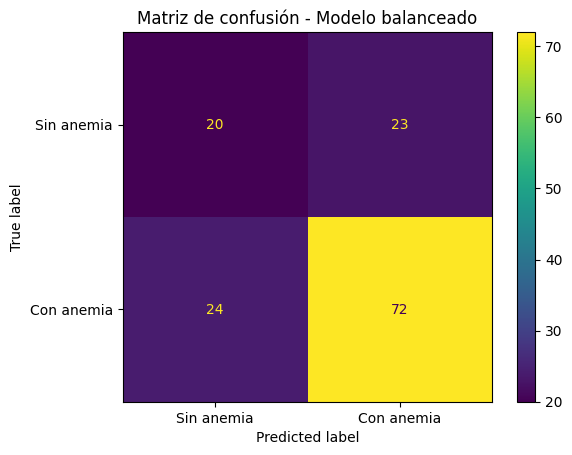

In [65]:
# ============================================================
# PASO 60: MATRIZ DE CONFUSIÓN DEL MODELO BALANCEADO
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_bal = confusion_matrix(
    y_test,
    y_pred_bal
)

print(cm_bal)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bal,
    display_labels=[
        "Sin anemia",
        "Con anemia"
    ]
)

disp.plot()

plt.title(
    "Matriz de confusión - Modelo balanceado"
)

plt.show()

In [66]:
# ============================================================
# PASO 61: COMPARACIÓN DE MODELOS
# Descripción: comparamos el modelo inicial y el modelo
# balanceado mediante las principales métricas de clasificación.
# ============================================================

import pandas as pd

comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Deep Learning inicial",
        "Deep Learning balanceado"
    ],
    "Accuracy": [
        accuracy,
        accuracy_bal
    ],
    "Precision": [
        precision,
        precision_bal
    ],
    "Recall": [
        recall,
        recall_bal
    ],
    "F1-score": [
        f1,
        f1_bal
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_bal
    ],
    "PR-AUC": [
        pr_auc,
        pr_auc_bal
    ]
})

comparacion_modelos.round(4)

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Deep Learning inicial,0.6906,0.6906,1.00,0.8170,0.6417,0.7792
1,Deep Learning balanceado,0.6619,0.7579,0.75,0.7539,0.6277,0.7679


In [67]:
# ============================================================
# PASO 62: REPORTE DEL MODELO BALANCEADO
# ============================================================

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_bal,
        target_names=[
            "Sin anemia",
            "Con anemia"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Sin anemia     0.4545    0.4651    0.4598        43
  Con anemia     0.7579    0.7500    0.7539        96

    accuracy                         0.6619       139
   macro avg     0.6062    0.6076    0.6068       139
weighted avg     0.6641    0.6619    0.6629       139



In [68]:
# ============================================================
# PASO 63: GUARDAR MODELO ENTRENADO
# ============================================================

modelo_balanceado.save(
    "modelo_anemia_puno_balanceado.keras"
)

print(
    "Modelo guardado correctamente."
)

Modelo guardado correctamente.


In [69]:
import joblib

joblib.dump(
    scaler,
    "scaler_anemia_puno.pkl"
)

print(
    "Scaler guardado correctamente."
)

Scaler guardado correctamente.
